### Data Understanding ### 


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 

acdc = "../data/acdc_dataset.csv"

#Argument sep to read the file with ; 
df = pd.read_csv(acdc,sep=";")


In [14]:
print("Dataset Dimention (Rows,Columns):", df.shape)

Dataset Dimention (Rows,Columns): (15465, 31)


In [15]:
df.head()

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,...,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,...,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,...,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,...,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,...,False,False,0,False,False,True,False,False,0,335.74


---
## 1.1 Feature Overview & Data Types

This line of code give us the total number of entries of the dataset as well as the total number of columns and their respective index and the data type(Dtype) of each column, we can also see the number of values which are not null for each variable(column).

In [16]:
print("\n--- Datatype Information ---")
df.info()


--- Datatype Information ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  object 
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  object 
 3   industry                     15465 non-null  object 
 4   country                      15035 non-null  object 
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  object 
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  object 
 10  membership_end               15465 non-null  object 
 11  last_badge_swipe             15465 non-null  object 
 12  days_since_last_visit        15465 non-null 

The dataset has different datatypes across 31 different variables (columns)

---
## 1.1.2 Numerical Variables:

 ### **Continuous:**


 **1.**  **Age**: <br>
**2.** **avg_weekly_visits:** <br>
**3.** **entitled_visits_last_period:**:<br>
**4.** **meeting_room_hours:** <br>
**5.** **event_space_hours:** <br>
**6.** **guest_passes_issued:** <br>
**7.** **lifetime_value**:<br>

### **Discrete:**

**8.** **n_colleagues_on_account:** <br>
**9.** **plan_days_per_week:** <br>
**10.** **days_since_last_visit:**:<br>
**11.** **total_visits:** <br>
**12.** **actual_visits_last_period**<br>
**13.**  **n_renewals:** <br>

## 1.2.3 Categorical Variables 

### Nominal Variables : 


**1.** **member_id:** <br>
**2.** **gender:** <br>
**3.** **industry:** <br>
**4.** **country:** <br>
**5.** **plan_tier:** <br>


### Temporal Variables:


**6.** **membership_start:** <br>
**7.** **membership_end:** <br>
**8.** **last_badge_swipe:** <br>

### Binary Variables:


**9.** **is_team_account:** <br>
**10.** **uses_meeting_rooms:** <br>
**11.** **uses_event_space:** <br>               
**12.** **uses_guest_passes:** <br>          
**13.** **uses_print:** <br>                  
**14.** **uses_mail_handling:** <br>            
**15.** **uses_phone_booths:** <br>               
**16.** **uses_day_passes:** <br>               
**17.** **uses_storage:** <br>                
**18.** **uses_bike_locker:** only 0.2% of the members use (39 in 15 465), <br>


---
 ## 1.1.4 Cardinality 

In [4]:
# Unique values per column compared with the number of customers
cardinality = pd.DataFrame({
    "non_missing": df.notna().sum(),
    "n_unique": df.nunique(),
    "categories_with_one_customer": df.apply(lambda col: (col.value_counts() == 1).sum()),
    "max_customers_per_category": df.apply(lambda col: col.value_counts().max() if col.notna().any() else 0)
})
cardinality["unique_pct_of_non_missing"] = (cardinality["n_unique"] / cardinality["non_missing"] * 100).round(1)
cardinality.sort_values("unique_pct_of_non_missing", ascending=False)

,non_missing,n_unique,categories_with_one_customer,max_customers_per_category,unique_pct_of_non_missing
member_id,15465,15450,15435,2,99.9
lifetime_value,14425,11860,11275,1725,82.2
meeting_room_hours,14167,1772,892,9250,12.5
entitled_visits_last_period,15465,1876,1013,4215,12.1
last_badge_swipe,15465,1543,354,279,10.0
membership_start,15465,1539,329,560,10.0
membership_end,15465,1423,306,3956,9.2
event_space_hours,15465,824,469,13695,5.3
total_visits,15465,810,118,652,5.2
avg_weekly_visits,15465,616,68,253,4.0


**1.**  **member_id:** has 99.9% unique values (15450 in 15465 rows), so ti is the unique identifier of each member, and since it carries no predictive information it will be remover further on before modeling . The 15 unique valuees will be handled later in the duplicates section.

**2.** Variables such as **lifetime_value**, **meeting_room_hours** or **total_visits** demonstrate high cardinality because they are continuous numeric vriables that take many different values. For example, **lifetime_value** has 11860 unique values in 14425 records (82.2%) ,which is expected for this type of variable.

**3.** Categorical Variables such as **industry** (43 unique values), **country** (33 unique values), **gender** (12 unique values) e **plan_tier** (19 unique values) reveal low to moderate cardinality. This will be useful for the encoding phase , since techniques like One-Hot Enconding and Label Enconding can be applied without creating too many columns. However, these counts are inflated due to inconsistencies (typos,casing,spaces,abbreviations) so the real number of categories is lower.   

**4.** Every column starting with uses_...  and the is_team_account variable have exactly two unique values, which indicates that they are binary variables(True/False or 1/0). 



## 1.2 Duplicates 

Member_id has 15465 rows but only 15450 unique values (as seen before in the cardinality analysis). So we need to check if the values are copies or members that are sharing the same id . 

In [6]:
n_dup_rows = df.duplicated().sum()
n_dup_ids  = df["member_id"].duplicated().sum()
print("Exact duplicate rows:", n_dup_rows)
print("Duplicated member_id:", n_dup_ids)

# Do any ids repeat with DIFFERENT content?
conflicting = df[df["member_id"].duplicated(keep=False) & ~df.duplicated(keep=False)]
print("Rows sharing an id but with different content:", len(conflicting))

df = df.drop_duplicates().reset_index(drop=True)
print("Shape after dropping duplicates:", df.shape, "| unique ids:", df["member_id"].is_unique)

Exact duplicate rows: 15
Duplicated member_id: 15
Rows sharing an id but with different content: 0
Shape after dropping duplicates: (15450, 31) | unique ids: True


**Conclusion:** the 15 member_id repeated ids are exact same copies of the whole row, so we can drop them safely.it´s also important to know that some copies differ on the text casing of a category(e.g HOT_DESK vs hot_desk) which is only detected after the categorical text standardization . 




   

### Data Preparation ###


### **Categorical Text Standarization** ###

Some categories are written inconsistently ( different casing , abbreviations,typos or even spaces) so the same category apears in different labels. To avoid this we build a normalized key (lower-case,trimmed ,no punctuation) and map it to one standard label.

## 1.3 Missing Values Audit

In [34]:
# Number and percentage of missing values per column
missing = pd.DataFrame({
    "n_missing": df.isna().sum(),
    "pct_missing": (df.isna().mean() * 100).round(1)
}).sort_values("n_missing", ascending=False)
missing

,n_missing,pct_missing
meeting_room_hours,1298,8.4
guest_passes_issued,1271,8.2
lifetime_value,1040,6.7
age,558,3.6
gender,530,3.4
country,430,2.8
plan_tier,105,0.7
n_colleagues_on_account,0,0.0
plan_days_per_week,0,0.0
membership_start,0,0.0


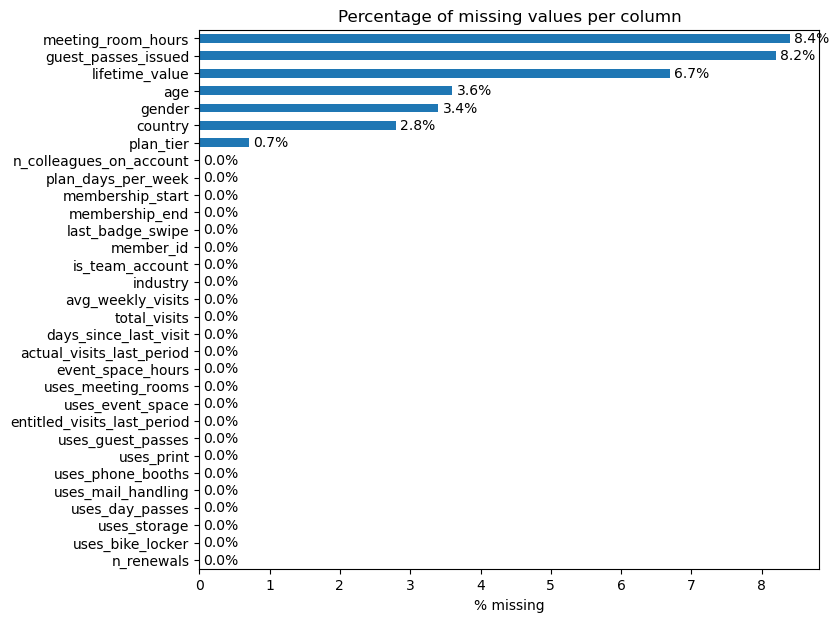

In [41]:
ax = missing["pct_missing"].plot(
    kind="barh",
    figsize=(8, 7),
    title="Percentage of missing values per column",
    xlabel="% missing"
)
plt.gca().invert_yaxis()

# Adiciona os valores com o símbolo "%" ao lado de cada barra
ax.bar_label(ax.containers[0], fmt='%.1f%%', padding=3)

plt.show()

Only 7 of the columns have missing values, all below 9%: "meeting_room_hours"(8.4%),"guest_passes_issued"(8.2%),"lifetime_value",(6.7%),"age"(3.6%),"gender"(3.4%),"country"(2.8%),"plan_tier"(0.7%).

**Note:** The absence of explicit missing values does not ensure data quality,because some columns use placeholder codes ('999','-1'.'1970-01-01') or contain impossible values that "is_na()" cannot detect.

--- 
## 1.4 Inconsitencies 

In [43]:
# Data type of each column
df.dtypes.to_frame("dtype")

,dtype
member_id,object
age,float64
gender,object
industry,object
country,object
is_team_account,bool
n_colleagues_on_account,int64
plan_tier,object
plan_days_per_week,int64
membership_start,object


We have age values above 100 years, which is almost impossible. We also check for members under 16, who are unlikely to hold a coworking membership. Both groups are counted in the code below. 

In [10]:
print((df["age"] > 100).sum())
df.loc[df["age"] > 100, ["member_id", "age"]].sort_values("age", ascending=False)

45


,member_id,age
12067,CW011720,149.0
2263,CW002199,147.0
5790,CW005627,146.0
10521,CW010226,146.0
3373,CW003272,145.0
1757,CW001712,144.0
1076,CW001047,144.0
10406,CW010114,143.0
2849,CW002763,142.0
3037,CW002944,142.0


In [9]:
df[(df["age"] < 16) | (df["age"] > 100)][["member_id", "age"]]

,member_id,age
11,CW000012,131.0
167,CW000163,4.0
179,CW000174,3.0
296,CW000290,9.0
305,CW000299,8.0
...,...,...
14921,CW014491,7.0
14949,CW014516,141.0
15049,CW014612,9.0
15256,CW014811,4.0


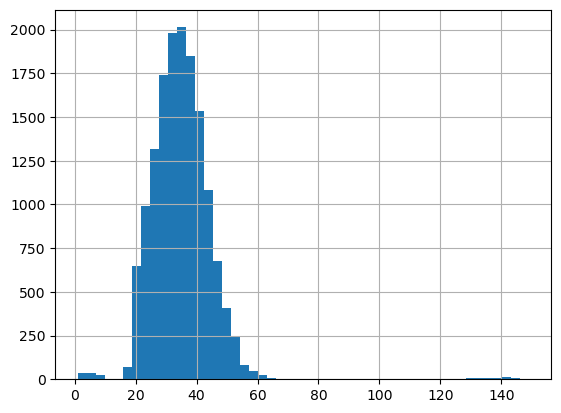

In [8]:
df["age"].hist(bins=50)
plt.show()

## 1.5 Descriptive Statistics: 

In [32]:
df.describe() 

,age,n_colleagues_on_account,plan_days_per_week,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_print,n_renewals
count,14907.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,15465.000000,14167.000000,15465.000000,14194.000000,15465.000000,15465.000000
mean,34.858724,0.537019,3.387262,117.109279,110.406531,1.777214,27.517393,13.800970,33.075570,5.117220,6.162956,0.323052,1.005496
std,10.394649,1.177668,1.458818,275.532807,182.939340,1.937515,13.480235,11.387207,428.169678,26.013097,23.444991,0.467658,1.353812
min,1.000000,-1.000000,0.000000,-956.000000,-112.000000,0.000000,0.000000,0.000000,-56.600000,-13.500000,-24.000000,0.000000,-3.000000
25%,29.000000,0.000000,2.000000,4.000000,8.000000,0.710000,17.390000,5.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,34.000000,0.000000,3.000000,13.000000,34.000000,1.420000,26.090000,10.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,40.000000,1.000000,5.000000,55.000000,132.000000,2.410000,43.480000,20.000000,7.200000,0.000000,0.000000,1.000000,2.000000
max,149.000000,9.000000,9.000000,1212.000000,6530.000000,47.400000,78.270000,60.000000,41220.000000,602.800000,589.000000,1.000000,6.000000


## **Outlier and Anomaly Detection** ##

### **Data Type Casting** ###